# 05 · ARDL、长期乘数与误差修正模型 (ECM)

notebook 04 的静态回归留下了强自相关的残差：通胀有惯性，油价的影响需要时间传导。
ARDL (autoregressive distributed lag) 模型同时包含被解释变量的滞后和解释变量的滞后，回答两个问题：

1. **动态**：油价上涨后，通胀在第 0、1、2…个季度分别变化多少？
2. **长期**：油价 *永久* 上涨 1% 后，价格水平最终累计变化多少？（长期传导 / long-run pass-through）

然后我们讨论误差修正表示 (ECM)、协整 (cointegration)，以及 **什么时候它们适用、什么时候不适用**。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

from statsmodels.tools.sm_exceptions import ValueWarning
from statsmodels.tsa.ardl import ARDL, UECM, ardl_select_order

from economic_lab.data import transforms as tf
from economic_lab.data.build import load_dataset
from economic_lab.econometrics.ardl import (
    ARDLResult, ardl_design, fit_ardl, fit_uecm, select_ardl_order,
)
from economic_lab.econometrics.ols import ols
from economic_lab.econometrics.timeseries import adf_test, ljung_box
from economic_lab.visualization import SERIES, use_lab_style

use_lab_style()
# statsmodels infers the quarterly frequency from the DatetimeIndex and warns; the inference is correct.
warnings.simplefilter("ignore", ValueWarning)
rng = np.random.default_rng(7)
q = load_dataset("quarterly")
DATA_KIND = q.attrs["data_kind"]
print("DATA KIND:", DATA_KIND.upper())

DATA KIND: REAL


## Part 1 · 经济直觉

* 零售燃油价格在几周内调整，但运输、航空、化肥等成本要经过合同期、库存周期才传导到最终价格，所以影响分布在多个季度（**distributed lag**）。
* 通胀本身有惯性（指数化合同、适应性预期），今天的通胀部分延续到下一季度（**autoregressive**）。
* 两者结合：即使油价只在一个季度上涨，惯性也会让影响持续若干季度。

**长期乘数** 回答政策制定者最关心的问题："如果油价永久性地高 10%，价格水平最终会高多少？"
这是一个关于 *价格水平* 的一次性移动，而不是永久更高的通胀率。

## Part 2 · 数学表述

ARDL($p,q$)：
$$\pi_t = c + \sum_{i=1}^{p}\phi_i\,\pi_{t-i} + \sum_{j=0}^{q}\beta_j\,\Delta o_{t-j} + \gamma\,\text{GST}_t + u_t.$$

| 符号 | 含义 | 单位 |
|---|---|---|
| $\pi_t$ | CPI 环比通胀 | % 每季度 |
| $\Delta o_t$ | NZD 油价对数变化 | 对数点 |
| $\phi_i$ | 通胀惯性 | 无量纲 |
| $\beta_j$ | 第 $j$ 期滞后的油价系数 | pp / 对数点 |
| $p, q$ | 滞后阶数 | 季度 |

稳定性条件：特征多项式 $1-\phi_1z-\dots-\phi_pz^p$ 的根都在单位圆外；对 ARDL(1, q) 即 $|\phi_1|<1$。在此条件下 $\sum\phi_i<1$。

## Part 3 · 推导

### 3.1 用滞后算子求动态乘数

令 $L$ 为滞后算子（$Lx_t=x_{t-1}$），$\phi(L)=1-\sum\phi_iL^i$，$\beta(L)=\sum\beta_jL^j$。模型可写成
$\phi(L)\pi_t = c + \beta(L)\Delta o_t + u_t$，所以
$$\pi_t = \frac{c}{\phi(1)} + \underbrace{\frac{\beta(L)}{\phi(L)}}_{\psi(L)=\sum_h\psi_hL^h}\Delta o_t + \frac{u_t}{\phi(L)}.$$

* **冲击乘数 (impulse)** $\psi_h = \partial\pi_{t+h}/\partial\Delta o_t$：油价变化 *一次性* 发生时，第 $h$ 季度的通胀反应。
* **累计 / 阶梯乘数 (step)** $\sum_{s=0}^{h}\psi_s$：$\Delta o$ 从第 0 期起 *每期* 都高 1 时，第 $h$ 期通胀的变化。
* **长期乘数**：令 $L=1$，
$$\theta = \psi(1) = \frac{\beta(1)}{\phi(1)} = \frac{\sum_j\beta_j}{1-\sum_i\phi_i}.$$

**经济解释的关键一步**：因为 $\pi$ 是价格水平的变化、$\Delta o$ 是油价水平的变化，
"油价水平一次性永久上涨 1%" 意味着 $\Delta o$ 只在第 0 期等于 1（一次脉冲）。
价格水平的累计反应 = 通胀反应之和 $\sum_h\psi_h = \theta$。所以在 *变化率* 上估计的 ARDL 中，$\theta$ 就是 **价格水平的长期传导弹性**（乘以 100 后的单位：% / %）。

### 3.2 长期乘数的标准误：delta 方法

$\hat\theta = g(\hat b)$ 是参数的非线性函数。一阶泰勒展开：$g(\hat b)\approx g(b)+\nabla g'(\hat b-b)$，所以
$$\operatorname{Var}(\hat\theta)\approx\nabla g'\,\widehat{\operatorname{Var}}(\hat b)\,\nabla g,\qquad
\frac{\partial\theta}{\partial\beta_j}=\frac{1}{1-\sum\phi_i},\quad\frac{\partial\theta}{\partial\phi_i}=\frac{\sum\beta_j}{(1-\sum\phi_i)^2}.$$
当 $\sum\phi_i$ 接近 1 时，分母接近 0，$\hat\theta$ 的分布高度非正态，delta 方法的置信区间不可靠 —— 可用模拟（Part 6）检查。

### 3.3 误差修正表示 (UECM)

以 ARDL(1,1) 为例，从 $y_t = c+\phi y_{t-1}+\beta_0x_t+\beta_1x_{t-1}+u_t$ 两边减去 $y_{t-1}$，并在右边加减 $\beta_0x_{t-1}$：
$$\Delta y_t = c + (\phi-1)y_{t-1} + (\beta_0+\beta_1)x_{t-1} + \beta_0\Delta x_t + u_t
= c + \alpha\,(y_{t-1}-\theta x_{t-1}) + \beta_0\Delta x_t + u_t,$$
其中 $\alpha=\phi-1$（**调整速度**，应为负），$\theta=(\beta_0+\beta_1)/(1-\phi)$。这只是 **同一个回归的重新参数化**：残差完全相同。
一般 ARDL($p,q$) 的 UECM：
$$\Delta y_t = c + \pi_y y_{t-1} + \pi_x x_{t-1} + \sum_{i=1}^{p-1}\psi_i\Delta y_{t-i} + \sum_{j=0}^{q-1}\omega_j\Delta x_{t-j} + u_t,\quad \theta=-\pi_x/\pi_y.$$

### 3.4 什么时候 ECM / 协整是合适的？

| 情形 | 合适的做法 |
|---|---|
| $y$、$x$ 都是 I(0)（通胀率、油价变化率） | 直接用 ARDL；$\theta$ 是长期乘数。**不需要协整**。 |
| $y$、$x$ 都是 I(1) 且 **协整**（$y_t-\theta x_t$ 平稳） | ECM：$\theta$ 是长期均衡关系，$\alpha$ 是调整速度。 |
| $y$、$x$ 都是 I(1) 但 **不协整** | 水平回归是伪回归，$\theta$ 无意义；只能用差分模型。 |

**Pesaran-Shin-Smith (2001) bounds test**：在 UECM 中检验 $H_0:\pi_y=\pi_x=0$（不存在水平关系）。F 统计量的分布是非标准的，
且依赖于回归元是 I(0) 还是 I(1)，所以有下界（全部 I(0)）和上界（全部 I(1)）两套临界值：
F 大于上界 → 拒绝 $H_0$（存在水平关系）；小于下界 → 不拒绝；介于两者之间 → 不确定。

### 3.5 滞后阶数选择

对每个候选 $(p,q)$ 计算 $\text{AIC}=-2\ell+2k$ 或 $\text{BIC}=-2\ell+k\ln n$，选择最小值。**必须在同一样本上比较**：
滞后越少可用的观测越多，如果每个模型用自己的最大样本，似然值不可比。`select_ardl_order` 从 $\max(p_{\max},q_{\max})$ 开始统一样本。
BIC 惩罚更重，在小样本中倾向于更简约的模型；AIC 偏向预测表现。

## Part 4 · 微型数值例子

从已知的 ARDL(1,1) 生成 20 个观测：$y_t = 0.2 + 0.5y_{t-1} + 0.3x_t + 0.1x_{t-1} + u_t$。真实长期乘数 $\theta=(0.3+0.1)/(1-0.5)=0.8$，调整速度 $\alpha=-0.5$。

In [2]:
n = 20
x = rng.normal(size=n)
u = 0.1 * rng.normal(size=n)
y = np.zeros(n)
for t in range(1, n):
    y[t] = 0.2 + 0.5 * y[t - 1] + 0.3 * x[t] + 0.1 * x[t - 1] + u[t]

# Build the regression by hand: rows t = 1..n-1, columns [1, y_{t-1}, x_t, x_{t-1}]
Y = y[1:]
X = np.column_stack([np.ones(n - 1), y[:-1], x[1:], x[:-1]])
print("X shape:", X.shape)
b = np.linalg.lstsq(X, Y, rcond=None)[0]
c_hat, phi_hat, b0_hat, b1_hat = b
theta_hat = (b0_hat + b1_hat) / (1 - phi_hat)
print(f"estimates: c={c_hat:.3f}, phi={phi_hat:.3f}, beta0={b0_hat:.3f}, beta1={b1_hat:.3f}")
print(f"long-run theta = {theta_hat:.3f} (true 0.8)")

# Dynamic multipliers by iterating the difference equation for a one-off unit change in x at t=0
psi = np.zeros(8)
for h in range(8):
    psi[h] = phi_hat * (psi[h - 1] if h > 0 else 0) + (b0_hat if h == 0 else 0) + (b1_hat if h == 1 else 0)
print("impulse multipliers psi_h:", psi.round(3))
print("cumulative:", psi.cumsum().round(3), "-> converges to theta")

X shape: (19, 4)
estimates: c=0.138, phi=0.558, beta0=0.277, beta1=0.076
long-run theta = 0.798 (true 0.8)
impulse multipliers psi_h: [0.277 0.23  0.129 0.072 0.04  0.022 0.012 0.007]
cumulative: [0.277 0.507 0.636 0.707 0.747 0.77  0.782 0.789] -> converges to theta


In [3]:
# UECM: Δy_t = c + pi_y y_{t-1} + pi_x x_{t-1} + omega_0 Δx_t
dY = np.diff(y)
Xe = np.column_stack([np.ones(n - 1), y[:-1], x[:-1], np.diff(x)])
be = np.linalg.lstsq(Xe, dY, rcond=None)[0]
print(f"pi_y (alpha) = {be[1]:.3f} = phi-1 = {phi_hat - 1:.3f}")
print(f"pi_x = {be[2]:.3f} = beta0+beta1 = {b0_hat + b1_hat:.3f}")
print(f"omega_0 = {be[3]:.3f} = beta0 = {b0_hat:.3f}")
print(f"theta from UECM = {-be[2] / be[1]:.3f}")
print("identical residuals:", np.allclose(Y - X @ b, dY - Xe @ be))

pi_y (alpha) = -0.442 = phi-1 = -0.442
pi_x = 0.352 = beta0+beta1 = 0.352
omega_0 = 0.277 = beta0 = 0.277
theta from UECM = 0.798
identical residuals: True


### 交互：ARDL(1,1) 的动态乘数

改变惯性 $\phi$ 和分布滞后系数，观察冲击乘数如何衰减、累计乘数如何收敛到 $\theta$。$\phi\to1$ 时长期乘数爆炸。

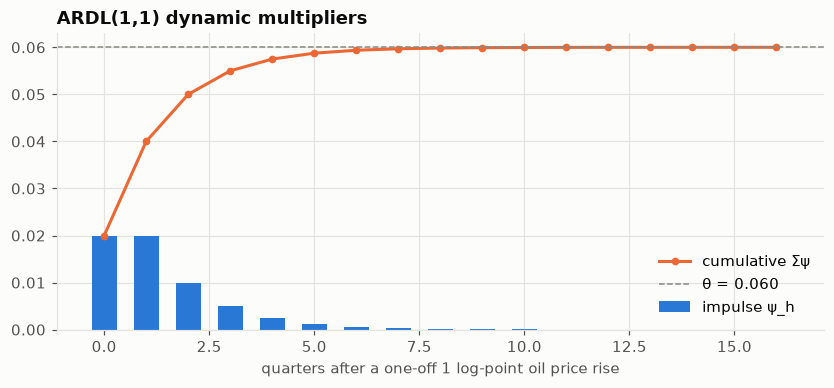

In [4]:
def plot_multipliers(phi=0.5, beta0=0.02, beta1=0.01, horizons=16):
    psi = np.zeros(horizons + 1)
    for h in range(horizons + 1):
        psi[h] = phi * (psi[h - 1] if h else 0) + (beta0 if h == 0 else 0) + (beta1 if h == 1 else 0)
    theta = (beta0 + beta1) / (1 - phi)
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.bar(range(horizons + 1), psi, color=SERIES[0], width=0.6, label="impulse ψ_h")
    ax.plot(range(horizons + 1), psi.cumsum(), color=SERIES[1], marker="o", label="cumulative Σψ")
    ax.axhline(theta, color="#8a8984", linestyle="--", linewidth=1, label=f"θ = {theta:.3f}")
    ax.set_xlabel("quarters after a one-off 1 log-point oil price rise")
    ax.set_title("ARDL(1,1) dynamic multipliers")
    ax.legend()
    plt.show()

try:
    from ipywidgets import FloatSlider, interact
    interact(plot_multipliers,
             phi=FloatSlider(value=0.5, min=0.0, max=0.95, step=0.05),
             beta0=FloatSlider(value=0.02, min=0.0, max=0.06, step=0.005, readout_format=".3f"),
             beta1=FloatSlider(value=0.01, min=-0.03, max=0.06, step=0.005, readout_format=".3f"),
             horizons=(4, 40, 2))
except ImportError:
    plot_multipliers()

## Part 5 · 库实现：`statsmodels.tsa.ardl`

`statsmodels` 的 `ARDL` 构建同样的滞后矩阵并用 OLS 估计；`UECM` 估计误差修正形式并提供 `bounds_test`。
在同一个 20 个观测的例子上对照：

In [5]:
ys, xs = pd.Series(y, name="y"), pd.Series(x, name="x")
ours = fit_ardl(ys, xs, 1, 1)
ref = ARDL(ys, 1, xs.to_frame(), 1, trend="c").fit()
print(pd.DataFrame({"ours": ours.ols.params.to_numpy(), "statsmodels": ref.params.to_numpy()}, index=ref.params.index))
print("\nour long-run table:\n", ours.long_run().round(4))

ours_e = fit_uecm(ys, xs, 1, 1)
ref_e = UECM(ys, 1, xs.to_frame(), 1, trend="c").fit()
print("\nUECM params equal:", np.allclose(ours_e.ols.params.to_numpy(), ref_e.params.to_numpy()))
print("bounds F: ours", round(ours_e.bounds_f_stat(), 4), "| statsmodels", round(ref_e.bounds_test(case=3).statistic, 4))

           ours  statsmodels
const  0.137958     0.137958
y.L1   0.558390     0.558390
x.L0   0.276785     0.276785
x.L1   0.075634     0.075634

our long-run table:
    long_run  std_err       z
x     0.798   0.1949  4.0954

UECM params equal: True
bounds F: ours 38.6392 | statsmodels 38.6392


`bounds_test(case=3)` 表示 "无限制常数项、无趋势"，与我们的 UECM 设定一致。我们自己计算 F 统计量（Wald 检验），
但非标准分布的临界值/p 值来自 `statsmodels`（它基于大规模模拟）。

## Part 6 · 真实数据：油价对新西兰通胀的动态传导

### 6.1 阶数选择

In [6]:
df = pd.DataFrame({
    "pi": tf.pct_change(q["cpi"], 1),
    "doil": tf.log_diff(q["oil_nzd"], 1),
}).dropna().loc["1992":]
df["gst"] = 0.0
df.loc[df.index.isin(pd.to_datetime(["1989-07-01", "2010-10-01"])), "gst"] = 1.0
HAS_GST = df["gst"].std() > 0
print(f"{DATA_KIND} data: n = {len(df)}, GST dummy active: {HAS_GST}")

orders = select_ardl_order(df["pi"], df[["doil"]], max_p=4, max_q=4, ic="bic")
print(orders.head(6).round(2))

sm_sel = ardl_select_order(df["pi"], 4, df[["doil"]], 4, ic="bic", trend="c")
print("\nstatsmodels ardl_select_order (BIC):", sm_sel.model.ardl_order)

real data: n = 138, GST dummy active: True
   p  q     aic     bic  nobs
0  2  0  151.35  162.94   134
1  1  0  157.91  166.60   134
2  3  0  152.70  167.18   134
3  2  1  152.78  167.27   134
4  4  0  151.16  168.55   134
5  2  2  151.45  168.84   134

statsmodels ardl_select_order (BIC): (2, 0)


阶数选择没有考虑 GST 虚拟变量（它只影响 2 个观测）。BIC 可能选择 $q=0$（只有当期油价）—— 但即使滞后系数单独不显著，
它们对长期乘数也有贡献。所以下面报告几种设定，看结论是否稳健，而不是只依赖一个 "最优" 模型。

### 6.2 估计与长期乘数（HAC 标准误）

In [7]:
def fit_spec(p, qo, frame=df, cov_type="HAC"):
    qs = {"doil": qo, **({"gst": 0} if frame["gst"].std() > 0 else {})}
    yy, X = ardl_design(frame["pi"], frame[list(qs)], p, qs)
    res = ols(yy, X, cov_type=cov_type, hac_lags=4)
    return ARDLResult(res, p, qs, "pi")

specs = [(1, 0), (1, 1), (2, 0), (2, 1), (2, 2), (4, 4)]
rows = []
for p, qo in specs:
    r = fit_spec(p, qo)
    lr = r.long_run().loc["doil"]
    lb = ljung_box(r.ols.resid, 8, model_df=p)
    rows.append({"p": p, "q": qo, "impact beta0": r.ols.params["doil_L0"], "sum phi": r.ar_sum,
                 "long run θ": lr["long_run"], "se(θ)": lr["std_err"], "BIC": r.ols.bic, "LB(8) p": lb["p_value"]})
robustness = pd.DataFrame(rows).round(4)
robustness

,p,q,impact beta0,sum phi,long run θ,se(θ),BIC,LB(8) p
0,1,0,0.0182,0.4101,0.0308,0.0071,163.2018,0.0000
1,1,1,0.0180,0.3970,0.0317,0.0069,167.9701,0.0000
2,2,0,0.0195,0.5573,0.0440,0.0125,153.2627,0.0039
3,2,1,0.0190,0.5280,0.0484,0.0125,156.3524,0.0108
4,2,2,0.0188,0.5981,0.0430,0.0144,155.8862,0.0462
5,4,4,0.0188,0.6261,0.0668,0.0260,165.8092,0.1915


In [8]:
P, Q = 2, 1
main = fit_spec(P, Q)
print(main.ols.summary_frame().round(4))
lr = main.long_run().loc["doil"]
print(f"\nARDL({P},{Q}) long-run pass-through θ = {lr['long_run']:.4f} (HAC delta-method se {lr['std_err']:.4f})")
print(f"=> a permanent 10% rise in NZD oil prices is associated with a {10 * lr['long_run']:.2f}% higher CPI level in the long run")
if DATA_KIND == "synthetic":
    p_ = q.attrs["true_params"]
    print(f"[synthetic] headline truth ≈ w_T * (b0+b1)/(1-rho_T) = {p_['w_T'] * (p_['b0'] + p_['b1']) / (1 - p_['rho_T']):.4f}")

           coef  std_err        t  p_value
const    0.2499   0.0670   3.7299   0.0002
pi_L1    0.2515   0.0875   2.8733   0.0041
pi_L2    0.2765   0.0651   4.2456   0.0000
doil_L0  0.0190   0.0024   7.8285   0.0000
doil_L1  0.0038   0.0025   1.5224   0.1279
gst_L0   1.6494   0.0716  23.0438   0.0000

ARDL(2,1) long-run pass-through θ = 0.0484 (HAC delta-method se 0.0125)
=> a permanent 10% rise in NZD oil prices is associated with a 0.48% higher CPI level in the long run


### 6.3 累计反应与模拟置信带

delta 方法给出 $\theta$ 的标准误，但整条累计反应曲线的不确定性更容易用 **参数模拟** 得到：
从 $N(\hat b, \hat V_{HAC})$ 中抽取 2000 组参数，每组计算一条累计反应曲线，取 5%/95% 分位数。
这同时让我们检查 $\hat\theta$ 的分布是否接近正态。

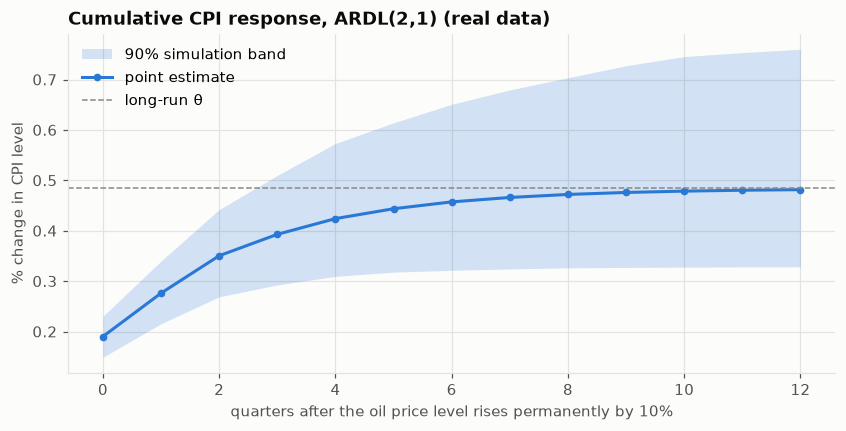

simulated θ: median 0.0484, 5–95%: 0.0328 to 0.0760


In [9]:
H = 12
point = main.cumulative_response("doil", H)
draws = rng.multivariate_normal(main.ols.params.to_numpy(), main.ols.cov_params.to_numpy(), size=2000)
names = main.ols.params.index
paths = np.array([main.cumulative_response("doil", H, params=pd.Series(d, index=names)).to_numpy() for d in draws])
lo_, hi_ = np.percentile(paths, [5, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(point.index, 10 * lo_, 10 * hi_, color=SERIES[0], alpha=0.2, linewidth=0, label="90% simulation band")
ax.plot(point.index, 10 * point, color=SERIES[0], marker="o", label="point estimate")
ax.axhline(10 * lr["long_run"], color="#8a8984", linestyle="--", linewidth=1, label="long-run θ")
ax.set_xlabel("quarters after the oil price level rises permanently by 10%")
ax.set_ylabel("% change in CPI level")
ax.set_title(f"Cumulative CPI response, ARDL({P},{Q}) ({DATA_KIND} data)")
ax.legend()
plt.show()

theta_draws = paths[:, -1]
print(f"simulated θ: median {np.median(theta_draws):.4f}, 5–95%: {np.percentile(theta_draws, 5):.4f} to {np.percentile(theta_draws, 95):.4f}")

### 6.4 水平关系：log CPI 与 log 油价是否协整？

notebook 03 显示两者都像 I(1)。如果它们协整，ECM 会给出 "CPI 水平与油价水平之间的长期均衡"。用 UECM + bounds test 检验：

In [10]:
lv = np.log(q[["cpi", "oil_nzd"]].dropna().loc["1992":])
lcpi, loil = lv["cpi"].rename("lcpi"), lv["oil_nzd"].rename("loil")
uecm = fit_uecm(lcpi, loil, 2, 2)
print(uecm.ols.summary_frame().round(4))
bt = UECM(lcpi, 2, loil.to_frame(), 2, trend="c").fit().bounds_test(case=3)
print(f"\nbounds F (ours) = {uecm.bounds_f_stat():.3f}; statsmodels: F = {bt.statistic:.3f}, "
      f"p(I(0) bound) = {bt.pvalue["lower"]:.3f}, p(I(1) bound) = {bt.pvalue["upper"]:.3f}")
print(f"implied 'long-run' θ = -pi_x/pi_y = {uecm.long_run:.3f}, alpha = {uecm.speed_of_adjustment:.4f}")

             coef  std_err       t  p_value
const     -0.0036   0.0162 -0.2227   0.8241
lcpi_L1    0.0002   0.0030  0.0788   0.9373
loil_L1    0.0013   0.0011  1.1427   0.2553
d_lcpi_L1  0.3795   0.0796  4.7678   0.0000
d_loil_L0  0.0191   0.0027  7.0859   0.0000
d_loil_L1  0.0001   0.0030  0.0181   0.9856



bounds F (ours) = 2.178; statsmodels: F = 2.178, p(I(0) bound) = 0.275, p(I(1) bound) = 0.488
implied 'long-run' θ = -pi_x/pi_y = -5.591, alpha = 0.0002


在真实数据中，bounds test 远不能拒绝 "无水平关系"，调整速度 $\alpha$ 接近 0 且不显著。
这时 $\hat\theta=-\pi_x/\pi_y$ 是两个都接近 0 的数之比，可以是任意大的数（真实数据下它大得离谱）—— **它没有经济意义**。

经济上这很合理：CPI 水平由货币政策、工资、汇率、其他所有商品价格共同决定，在通胀目标制下趋势性上升；
油价水平在 30 年间大幅波动、没有趋势回归到 CPI 的某个固定比例的理由。**油价与 CPI 水平之间不存在稳定的长期均衡**，
所以正确的框架是 6.2 节中 "变化率上的 ARDL"，其中的 $\theta$ 是累计传导，而不是协整系数。

### 6.5 总体 vs tradable vs non-tradable

经济直觉：燃油本身属于 **tradable** 商品（价格由国际市场决定，以 NZD 计价），所以油价应主要通过 tradable CPI 传导；
**non-tradable**（房租、本地服务等）主要由国内需求和工资决定，直接传导应接近 0，只能通过运输成本、工资和预期间接受影响。

检验方法：对三个价格指数估计同一个 ARDL(2,1)，样本统一为 tradable / non-tradable 数据都可用的 1999Q3 以后，
只有 2010Q4 一个 GST 虚拟变量。如果总体 CPI ≈ $w_T \times$ tradable + $(1-w_T)\times$ non-tradable，那么总体的 $\theta$
应大约是两者的加权平均（tradable 在 CPI 中的权重约 0.4–0.45）。

In [11]:
doil_q = tf.log_diff(q["oil_nzd"].dropna(), 1, freq="Q")
rows = []
for col in ["cpi", "cpi_tradable", "cpi_nontradable"]:
    f = pd.DataFrame({"pi": tf.pct_change(q[col].dropna(), 1, freq="Q"), "doil": doil_q}).dropna().loc["1999-07-01":]
    f["gst"] = f.index.isin(pd.to_datetime(["2010-10-01"])).astype(float)
    r = fit_spec(P, Q, f)
    lr_c = r.long_run().loc["doil"]
    rows.append({"series": col, "n": len(r.ols.resid),
                 "impact β0": r.ols.params["doil_L0"], "se(β0)": r.ols.summary_frame().loc["doil_L0", "std_err"],
                 "long-run θ": lr_c["long_run"], "se(θ)": lr_c["std_err"],
                 "LB(8) p": ljung_box(r.ols.resid, 8, model_df=P)["p_value"]})
by_component = pd.DataFrame(rows).set_index("series").round(4)
print(f"ARDL({P},{Q}) by CPI component, {f.index[0]:%Y}Q{f.index[0].quarter}–{f.index[-1]:%Y}Q{f.index[-1].quarter} ({DATA_KIND} data)")
print(by_component)
if DATA_KIND == "synthetic":
    tp = q.attrs["true_params"]
    print(f"[synthetic] true tradable θ = (b0+b1)/(1-rho_T) = {(tp['b0'] + tp['b1']) / (1 - tp['rho_T']):.4f}; "
          "non-tradable has no direct oil term (true θ = 0)")

ARDL(2,1) by CPI component, 1999Q3–2026Q2 (real data)
                   n  impact β0  se(β0)  long-run θ   se(θ)  LB(8) p
series                                                              
cpi              106     0.0195  0.0025      0.0490  0.0123   0.0013
cpi_tradable     106     0.0414  0.0051      0.0809  0.0156   0.0065
cpi_nontradable  106     0.0008  0.0022      0.0092  0.0086   0.0000


**解读**（数字对应真实数据 RBNZ M1，1999Q3–2026Q2，n = 106；合成数据下数字不同）：

* **tradable**：当期影响 $\beta_0 \approx 0.041$，长期 $\theta \approx 0.081$（se 0.016）→ NZD 油价永久上涨 10%，
  tradable CPI 水平长期约高 0.8%。
* **non-tradable**：$\beta_0 \approx 0.001$，$\theta \approx 0.009$（se 0.009），统计上与 0 无差别。
* **总体**：$\theta \approx 0.049$，介于两者之间，与 "加权平均" 的直觉一致（但并不精确相等：三个 ARDL 是分别估计的，动态结构不同）。

这是一个 **合理性检验 (sanity check)**：结果符合 "燃油是 tradable 商品" 的经济机制。但它仍然是条件相关，不是因果效应 ——
识别问题见下面第 4 点。另外三个模型的残差都有显著自相关（LB p < 0.01），尤其是 non-tradable：它的季节性和持续性更强，
ARDL(2,1) 没有完全捕捉；HAC 标准误对此是稳健的，但点估计的效率会受影响（练习 2 的季度虚拟变量是自然的改进）。

## Part 7 · 诊断与解释

Ljung-Box(8) on ARDL residuals: {'Q': 16.6228, 'df': 6, 'p_value': 0.0108}


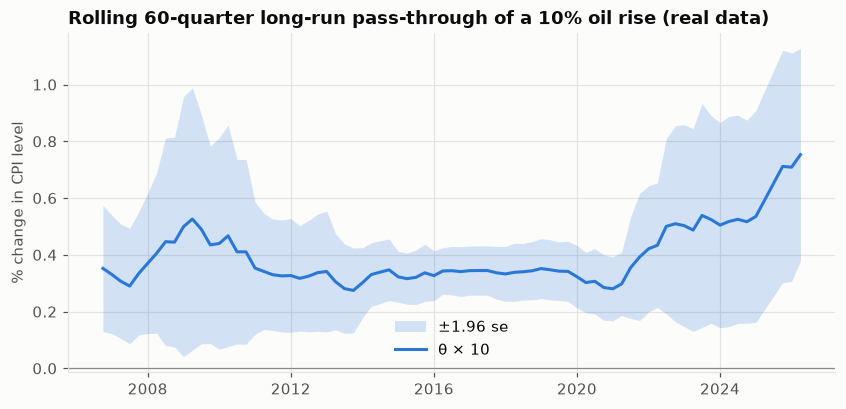

In [12]:
resid = main.ols.resid
print("Ljung-Box(8) on ARDL residuals:", {k: round(v, 4) for k, v in ljung_box(resid, 8, model_df=P).items()})

window = 60
roll = {}
for end in range(window, len(df) + 1):
    sub = df.iloc[end - window:end]
    try:
        roll[sub.index[-1]] = fit_spec(P, Q, sub).long_run().loc["doil", ["long_run", "std_err"]]
    except ValueError:
        continue
roll = pd.DataFrame(roll).T
fig, ax = plt.subplots()
ax.fill_between(roll.index, 10 * (roll.long_run - 1.96 * roll.std_err), 10 * (roll.long_run + 1.96 * roll.std_err),
                color=SERIES[0], alpha=0.2, linewidth=0, label="±1.96 se")
ax.plot(roll.index, 10 * roll.long_run, color=SERIES[0], label="θ × 10")
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_title(f"Rolling {window}-quarter long-run pass-through of a 10% oil rise ({DATA_KIND} data)")
ax.set_ylabel("% change in CPI level")
ax.legend()
plt.show()

**解读要点**

1. 当期影响 $\beta_0$ 在不同设定中都很稳定；长期乘数 $\theta$ 对滞后阶数更敏感（表 6.2），因为它放大了 $\sum\phi_i$ 的不确定性。
   这是报告一个区间、而非一个数字的理由。
2. 残差自相关比静态模型大大减少，但未必完全消失（看 Ljung-Box p 值）。总体 CPI 未季调，季度虚拟变量是一个自然的扩展（练习 2）。
3. 滚动估计显示传导是否随时间变化。燃油在 CPI 篮子中的权重、汇率制度、通胀预期的锚定程度都会改变传导。
4. **识别**：$\theta$ 仍然是条件相关。油价变化包含全球需求和供给冲击，新西兰的需求与全球需求相关。
   ARDL 解决了 *动态* 设定问题，没有解决 *内生性* 问题。Track B（SVAR、局部投影）会用外部识别的油价冲击。
5. **总体 vs tradable**：6.5 节显示传导几乎全部来自 tradable 部分，non-tradable 的直接传导与 0 无差别。
   Track B 中应分别对 tradable / non-tradable 估计冲击响应。

**面试版一句话**：*"在通胀率上估计 ARDL，而不是在价格水平上估计 ECM，因为 log CPI 与 log 油价都是 I(1) 且 bounds test 不支持协整；
长期传导 θ 用 delta 方法和参数模拟给出不确定性，并对滞后阶数做稳健性检验。"*

## Part 8 · 练习

1. **Easy** — 把主设定改为 ARDL(1,1) 和 ARDL(4,4)，长期乘数及其标准误如何变化？为什么 (4,4) 的标准误更大？
2. **Intermediate** — 把 $\Delta o_t$ 拆成美元油价变化 $\Delta o^{USD}_t$ 和汇率变化 $\Delta e_t$，估计 ARDL(2, {1,1})，比较两者的长期乘数。
3. **Advanced** — Monte Carlo：(a) 生成两个独立的随机游走，(b) 生成两个协整序列 $y_t = 0.5x_t + \text{AR}(1, 0.5)$，$x_t$ 为随机游走。
   各 500 次，n=120，计算 bounds test 在 5% 水平（用 I(1) 上界的 p 值）的拒绝率。哪个是 size，哪个是 power？

## 参考答案

In [13]:
# Exercise 1
for p, qo in [(1, 1), (4, 4)]:
    r = fit_spec(p, qo)
    print(f"ARDL({p},{qo}):", r.long_run().loc["doil"].round(4).to_dict(), "sum phi =", round(r.ar_sum, 3))
# More parameters -> each estimated less precisely; θ is a ratio, so noise in sum(phi) and sum(beta) compounds.

ARDL(1,1): {'long_run': 0.0317, 'std_err': 0.0069, 'z': 4.6276} sum phi = 0.397


ARDL(4,4): {'long_run': 0.0668, 'std_err': 0.026, 'z': 2.573} sum phi = 0.626


In [14]:
# Exercise 2
df2 = df.join(pd.DataFrame({"doil_usd": tf.log_diff(q["brent_usd"], 1), "dfx": tf.log_diff(q["nzd_usd"], 1)}))
qs = {"doil_usd": 1, "dfx": 1, **({"gst": 0} if HAS_GST else {})}
yy, X = ardl_design(df2["pi"], df2[list(qs)], 2, qs)
r = ARDLResult(ols(yy, X, cov_type="HAC", hac_lags=4), 2, qs, "pi")
print(r.long_run().round(4))

          long_run  std_err       z
doil_usd    0.0488   0.0122  4.0131
dfx        -0.0632   0.0237 -2.6702
gst         3.5125   0.8317  4.2230


In [15]:
# Exercise 3
from economic_lab.econometrics.timeseries import simulate_ar1

def bounds_rejection(cointegrated, reps=500, n=120, seed=0):
    r = np.random.default_rng(seed)
    rejections = 0
    for i in range(reps):
        x_ = np.cumsum(r.standard_normal(n))
        if cointegrated:
            y_ = 0.5 * x_ + simulate_ar1(n, 0.5, seed=seed * 100_000 + i)
        else:
            y_ = np.cumsum(r.standard_normal(n))
        res = UECM(pd.Series(y_, name="y"), 1, pd.DataFrame({"x": x_}), 1, trend="c").fit()
        rejections += res.bounds_test(case=3).pvalue["upper"] < 0.05
    return rejections / reps

print("size  (no cointegration):", bounds_rejection(False))
print("power (cointegrated)    :", bounds_rejection(True))

size  (no cointegration): 0.11


power (cointegrated)    : 1.0


第一个是检验的 **size**（$H_0$ 为真时的拒绝率），第二个是 **power**（$H_0$ 为假时的拒绝率）。

**size 明显高于 5%**（500 次重复的 Monte Carlo 标准误约为 $\sqrt{0.05\times0.95/500}\approx1\%$，所以这不是模拟噪声）。
原因：`statsmodels` 使用的是 **渐近** 临界值，而 n = 120 时 F 统计量的有限样本分布右尾更厚。
Narayan (2005) 为 n = 30–80 提供了更大的小样本临界值，正是为了修正这种过度拒绝。启示：

* 小样本中 bounds test **拒绝** "无协整" 时要谨慎 —— 可能是假阳性；
* 本 notebook 真实数据的结论是 **不拒绝**，过度拒绝的倾向只会让 "不存在水平关系" 的结论更可信。

power 接近 1，因为这里的调整速度很快（偏离是 AR(1) 系数 0.5）。把它改为 0.9 再运行，power 会明显下降 —— 这就是小样本中难以确认协整的原因。